In [1]:
import sys
sys.path.append("..")

from src.dataset import build_dataset

df = build_dataset("../data/raw/owid-co2-data.csv",
                   "../data/raw/owid-energy-data.csv")
df.shape

(16964, 28)

In [2]:
df.isna().mean().mul(100).round(1).sort_values(ascending=False)

fossil_fuels_energy_share_pct    77.7
gas_energy_twh                   76.2
gas_energy_share_pct             76.2
coal_energy_share_pct            75.0
coal_energy_twh                  75.0
renewables_energy_twh            73.2
renewables_energy_share_pct      73.2
oil_energy_twh                   73.2
oil_energy_share_pct             73.2
low_carbon_energy_share_pct      73.2
gas_co2                          43.2
nuclear_energy_share_pct         41.9
total_energy_per_capita_kwh      40.4
total_energy_twh                 40.1
nuclear_energy_twh               39.9
co2_per_gdp                      32.4
coal_co2                         32.2
gdp                              31.8
cement_co2                       13.2
oil_co2                          12.9
co2_per_capita                   11.6
share_global_co2                 10.9
cumulative_co2                   10.9
co2                              10.9
population                        1.1
year                              0.0
iso_code    

In [3]:
coverage = df.groupby("year")[["co2", "gdp", "total_energy_twh"]].count()
coverage.loc[1900::10]

,co2,gdp,total_energy_twh
year,,,
1900,42,36,0
1910,50,39,0
1920,56,40,0
1930,62,43,0
1940,67,41,0
1950,90,87,0
1960,91,87,0
1970,100,95,65
1980,176,139,182


In [4]:
for col in ["co2", "gdp", "total_energy_twh", "coal_energy_twh", "renewables_energy_twh"]:
    has_data = df[df[col].notna()]
    print(col, has_data["year"].min(), has_data["year"].max(), has_data["country"].nunique())

co2 1750 2025 210
gdp 1820 2022 164
total_energy_twh 1965 2025 209
coal_energy_twh 1965 2025 79
renewables_energy_twh 1965 2025 79


In [ ]:
mix = df[df["coal_energy_twh"].notna()]

# 1) the 79 countriesss
print(sorted(mix["country"].unique()))

# 2) how many of them have data in each recent year
print(mix.groupby("year")["country"].nunique().loc[[1965, 1980, 1990, 2000, 2010, 2020, 2022, 2024, 2025]])

['Algeria', 'Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bangladesh', 'Belarus', 'Belgium', 'Brazil', 'Bulgaria', 'Canada', 'Chile', 'China', 'Colombia', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Ecuador', 'Egypt', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hong Kong', 'Hungary', 'Iceland', 'India', 'Indonesia', 'Iran', 'Iraq', 'Ireland', 'Israel', 'Italy', 'Japan', 'Kazakhstan', 'Kuwait', 'Latvia', 'Lithuania', 'Luxembourg', 'Malaysia', 'Mexico', 'Morocco', 'Netherlands', 'New Zealand', 'North Macedonia', 'Norway', 'Oman', 'Pakistan', 'Peru', 'Philippines', 'Poland', 'Portugal', 'Qatar', 'Romania', 'Russia', 'Saudi Arabia', 'Singapore', 'Slovakia', 'Slovenia', 'South Africa', 'South Korea', 'Spain', 'Sri Lanka', 'Sweden', 'Switzerland', 'Taiwan', 'Thailand', 'Trinidad and Tobago', 'Turkey', 'Turkmenistan', 'Ukraine', 'United Arab Emirates', 'United Kingdom', 'United States', 'Uzbekistan', 'Venezuela', 'Vietnam']
year
1965    56
1980    59
1990    74
2000    75
2010

In [6]:
mix_countries = set(mix["country"])

# 1) are the big countries inside the group?
big = ["China", "United States", "India", "Russia", "Japan", "Germany", "Brazil", "Italy", "Iran", "Saudi Arabia"]
print("in:", [c for c in big if c in mix_countries])
print("out:", [c for c in big if c not in mix_countries])

# 2) what share of CO2 (among our 210 countries) do these countries cover in 2022?
y2022 = df[df["year"] == 2022]
covered = y2022[y2022["country"].isin(mix_countries)]["co2"].sum()
total = y2022["co2"].sum()
print(round(covered / total * 100, 1), "%")

in: ['China', 'United States', 'India', 'Russia', 'Japan', 'Germany', 'Brazil', 'Italy', 'Iran', 'Saudi Arabia']
out: []
96.8 %


In [7]:
from src.analysis import change_between, find_decoupled

changes = change_between(df, 1990, 2022)
print(changes.shape)

decoupled = find_decoupled(changes)
print(len(decoupled))
decoupled.sort_values("co2_change_pct")

(155, 2)
37


,gdp_change_pct,co2_change_pct
country,,
Estonia,47.785832,-67.562381
Latvia,21.728318,-66.383501
Lithuania,66.230793,-63.990461
Romania,294.459384,-61.245691
Slovakia,130.898833,-48.727613
United Kingdom,73.689585,-48.433890
Belarus,50.266295,-47.334373
Denmark,98.027540,-44.740745
Czechia,134.638349,-42.149871


In [11]:
changes_2000 = change_between(df, 2000, 2022)
decoupled_2000 = find_decoupled(changes_2000)
print(len(decoupled_2000))
both = decoupled.index.intersection(decoupled_2000.index)
print(len(both))
print(sorted(both))

42
29
['Austria', 'Belgium', 'Croatia', 'Cuba', 'Czechia', 'Denmark', 'Estonia', 'Finland', 'France', 'Germany', 'Greece', 'Hungary', 'Italy', 'Jamaica', 'Japan', 'Latvia', 'Luxembourg', 'Malta', 'Netherlands', 'North Macedonia', 'Poland', 'Portugal', 'Romania', 'Slovakia', 'Slovenia', 'Sweden', 'Switzerland', 'United Kingdom', 'United States']


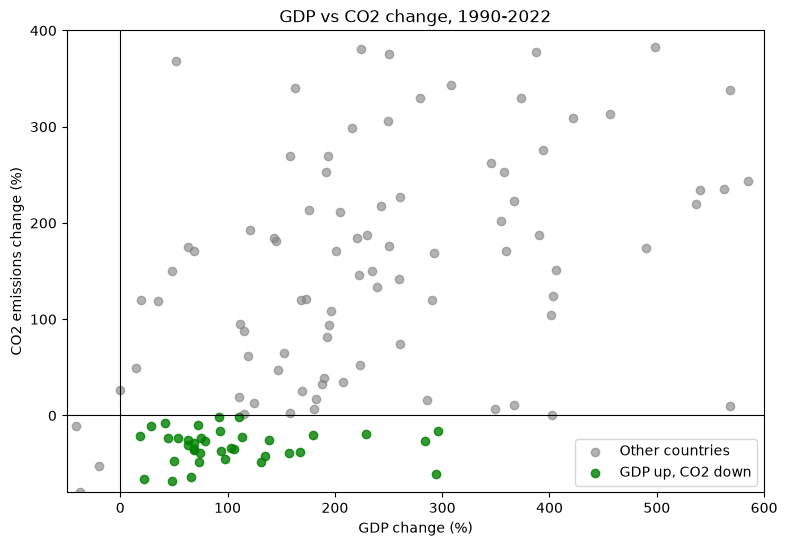

In [12]:
import importlib
import src.visualization
importlib.reload(src.visualization)
from src.visualization import plot_change_scatter

fig = plot_change_scatter(
    changes, decoupled, "GDP vs CO2 change, 1990-2022",
    xlim=(-50, 600), ylim=(-80, 400),
)